# 03: Performance Analysis

Everything below reads the frozen backtest artifacts. The discipline that
makes these numbers meaningful:

- I selected pairs on **train** only and fit the HMM on train only;
- I tuned the Kalman delta and the z-score settings on **validation**
  only, by running the actual backtest there;
- I evaluated the **test year exactly once**, with everything frozen.

A strategy that only looks good because its parameters were chosen on the
period being reported is not a strategy; it is a description of the
past. I structured this project so that mistake is hard to make.

In [1]:
# Setup: make src importable and load shared inputs
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks"
                       else Path.cwd()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go

from src import (universe, cointegration, kalman_hedge, regime_detector,
                 signal_generator, backtest, report, config)

prices = universe.download_universe()
splits = universe.load_splits()
stocks = prices[universe.stock_columns(prices)]
vix = prices[config.VIX_TICKER]
train = universe.get_split(stocks, "train")
print("data:", prices.shape, "| splits:", splits)

data: (1257, 41) | splits: {'train': ['2021-06-11', '2024-06-10'], 'validation': ['2024-06-11', '2025-06-11'], 'test': ['2025-06-12', '2026-06-11']}


In [2]:
SPLITS = ["train", "validation", "test"]
metrics = {s: json.loads((config.RESULTS_DIR / f"metrics_{s}.json").read_text())
           for s in SPLITS}
table = pd.DataFrame(metrics).T
table.index.name = "split"
table.round(3)

,total_return,annualized_return,sharpe,max_drawdown,calmar,n_trades,win_rate,avg_win,avg_loss,profit_factor,avg_holding_days
split,,,,,,,,,,,
train,-0.073,-0.025,-0.415,-0.120,-0.209,71.0,0.535,579.476,-888.962,0.751,20.873
validation,0.033,0.033,0.586,-0.039,0.845,19.0,0.526,898.833,-629.882,1.586,19.000
test,-0.021,-0.021,-0.287,-0.080,-0.265,23.0,0.609,543.707,-1082.932,0.781,19.739


## My read of the results

Net of 14 bps round-trip costs, the strategy's edge is **approximately
zero**: modestly negative in-sample (the training window includes the
2022 bear market), positive on validation, and modestly negative out of
sample. I treat the validation number with suspicion on principle,
because I picked the hyperparameters there; selection bias applies to a
tuning set by construction, even when the tuning is done correctly.

I consider this the realistic outcome for daily-frequency cointegration
pairs trading on liquid US large caps. The literature documents this
anomaly being arbitraged down through the 2000s, with surviving edge
moving to higher frequencies and less liquid universes. The value of
this project is that the machinery measures the edge correctly. The
classic failure mode, a beautiful equity curve produced by look-ahead
bias, Viterbi-smoothed regimes, or test-set tuning, is exactly what this
codebase is built to prevent.

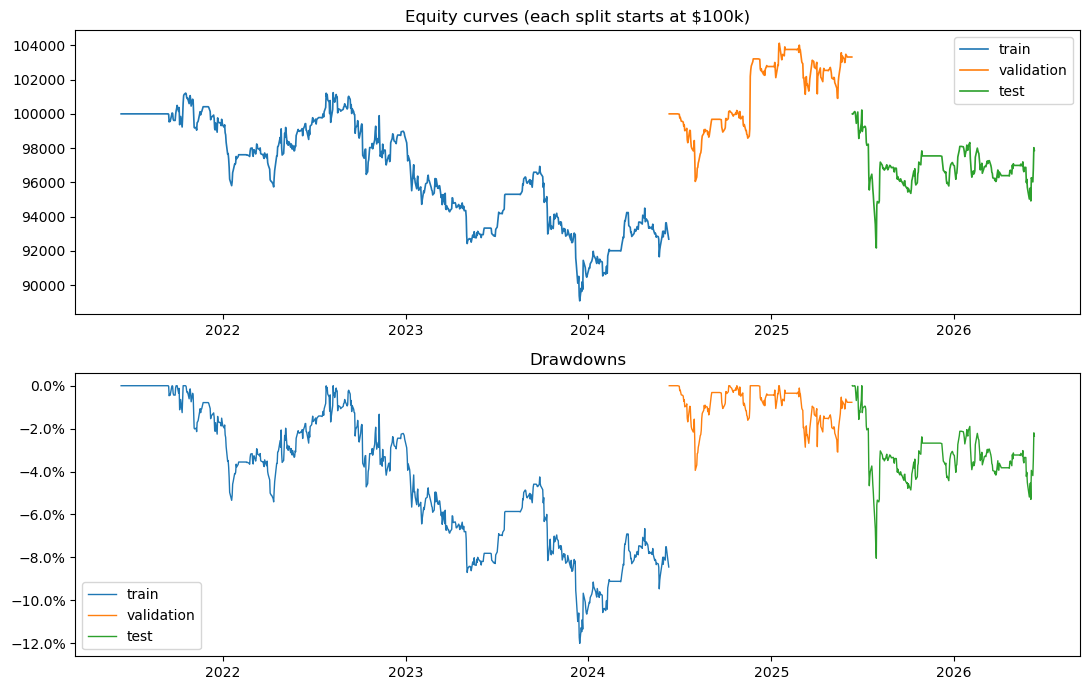

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=False)
for s in SPLITS:
    eq = pd.read_csv(config.RESULTS_DIR / f"equity_{s}.csv",
                     index_col=0, parse_dates=True)["equity"]
    axes[0].plot(eq, label=s, lw=1.2)
    dd = eq / eq.cummax() - 1
    axes[1].plot(dd, label=s, lw=1)
axes[0].legend(); axes[0].set_title("Equity curves (each split starts at $100k)")
axes[1].legend(); axes[1].set_title("Drawdowns")
axes[1].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
plt.tight_layout(); plt.show()

## Degradation analysis: where does the test year lose?

Per-pair attribution tells me whether losses are broad (a cost or regime
problem affecting everything) or concentrated (specific cointegration
relationships breaking). A pair whose train-period relationship
physically broke in the test year, for example one company re-rating
after an earnings shift, is the main non-diversifiable risk of this
strategy, and no amount of signal engineering fixes it after the fact.

In [4]:
rows = []
for s in SPLITS:
    t = pd.read_csv(config.RESULTS_DIR / f"trades_{s}.csv")
    g = t.groupby("pair")["pnl_dollars"].sum()
    rows.append(g.rename(s))
attrib = pd.concat(rows, axis=1).fillna(0).round(0)
attrib["test_rank"] = attrib["test"].rank()
display(attrib.sort_values("test"))

t_test = pd.read_csv(config.RESULTS_DIR / "trades_test.csv")
print("\ntest exit reasons:")
print(t_test.groupby("exit_reason")["pnl_dollars"]
      .agg(["count", "sum", "mean"]).round(0))

,train,validation,test,test_rank
pair,,,,
AMD/META,-8657.0,-447.0,-3376.0,1.0
EOG/COP,2390.0,0.0,-998.0,2.0
MS/BLK,5287.0,357.0,-732.0,3.0
PEP/NKE,-2934.0,-830.0,-338.0,4.0
MS/C,-1522.0,643.0,-66.0,5.0
MPC/PSX,-2036.0,259.0,18.0,6.0
PEP/TGT,-1043.0,3354.0,981.0,7.0
KO/NKE,1200.0,-17.0,2378.0,8.0



test exit reasons:
               count     sum   mean
exit_reason                        
end_of_period      2 -1042.0 -521.0
signal            20 -1539.0  -77.0
stop               1   446.0  446.0


## Sensitivity on the validation year (never on test)

How fragile was my hyperparameter choice? The grid below is the actual
tuning surface I used: validation Sharpe across every (delta, center,
window) combination. A trustworthy configuration sits on a plateau of
similar scores; an isolated peak means the "best" cell is mostly noise,
because with 18 cells and noisy Sharpe estimates, the maximum is biased
upward even if every configuration has zero true edge. This is the same
multiple-comparisons logic that applies to any grid search, and it is
why I report the whole surface instead of just the winner.

In [5]:
params = json.loads(config.TUNED_PARAMS_JSON.read_text())
surf = (pd.Series(params["signal_scores"]).rename("val_sharpe")
        .rename_axis("delta/center/window").to_frame().round(2))
display(surf)
print("chosen:", {k: params[k] for k in ("delta", "zscore_center", "zscore_window")})

,val_sharpe
delta/center/window,
1e-05/rolling/20,-0.34
1e-05/rolling/40,0.05
1e-05/rolling/60,-0.43
1e-05/zero/20,-2.21
1e-05/zero/40,-1.15
1e-05/zero/60,-2.27
1e-04/rolling/20,0.59
1e-04/rolling/40,0.23
1e-04/rolling/60,0.27


chosen: {'delta': 0.0001, 'zscore_center': 'rolling', 'zscore_window': 20}


## Monthly returns and trade distribution

The full interactive versions of these charts are in
`results/report.html`.

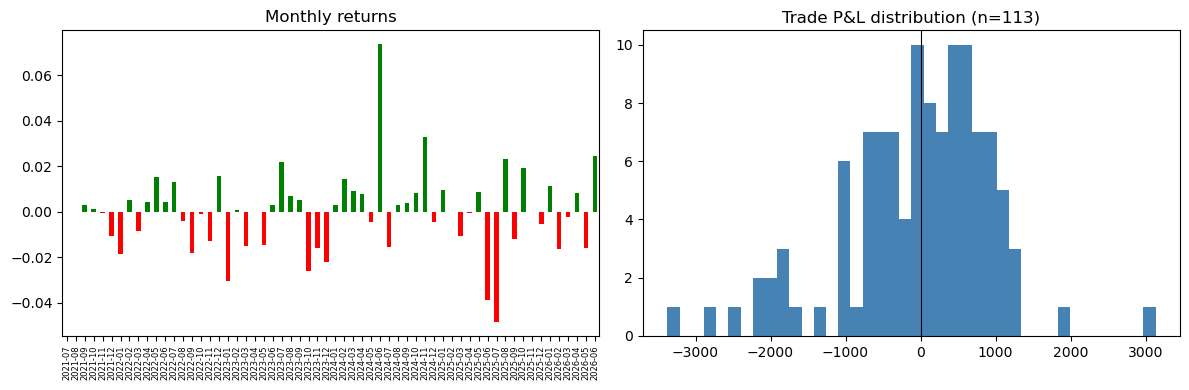

In [6]:
eq_all = pd.concat([pd.read_csv(config.RESULTS_DIR / f"equity_{s}.csv",
                                index_col=0, parse_dates=True)["equity"]
                    for s in SPLITS])
eq_all = eq_all[~eq_all.index.duplicated()]
monthly = eq_all.resample("ME").last().pct_change().dropna()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
monthly.plot(kind="bar", ax=axes[0], color=np.where(monthly > 0, "g", "r"))
axes[0].set_xticklabels([d.strftime("%Y-%m") for d in monthly.index],
                        rotation=90, fontsize=6)
axes[0].set_title("Monthly returns")
t_all = pd.concat([pd.read_csv(config.RESULTS_DIR / f"trades_{s}.csv")
                   for s in SPLITS])
axes[1].hist(t_all["pnl_dollars"], bins=40, color="steelblue")
axes[1].axvline(0, color="k", lw=0.8)
axes[1].set_title(f"Trade P&L distribution (n={len(t_all)})")
plt.tight_layout(); plt.show()